In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

In [22]:
import re
import json
import keras
import datasets
import numpy as np
import sklearn.metrics
import tqdm.notebook as tqdm

In [3]:
class BPE:

    word_split = re.compile(r'\b')
    spaces = re.compile(r'\s')

    def __init__(self, tokens, vocab, merges, allowed, max_size):
        self.tokens = tokens
        self.vocab = vocab
        self.merges = merges
        self.allowed = set(allowed)
        self.max_size = max_size

    def encode(self, sentence: str) -> list[int]:
        words = [[self.vocab[i] for i in word] for word in self._splitted(sentence, self.allowed)]
        for word in words:
            while True:
                for i in range(0, len(word) - 1):
                    if (idx := word[i] * self.max_size + word[i + 1]) in self.merges:
                        idx = self.merges[idx]
                        break
                else:
                    break

                word[i:i + 2] = idx,

        return [j for i in words for j in i]

    def decode(self, ids) -> str:
        return ''.join(self.tokens[i].replace('|', ' ') for i in ids)

    def add_token(self, token: str) -> int:
        token_id = len(self.tokens)
        self.tokens.append(token)
        self.vocab[token] = token_id
        return token_id

    @classmethod
    def _splitted(cls, sentence: list[str], allowed: set):
        sentence = ''.join(i for i in sentence if i in allowed).strip()
        last = ''
        for i, word in enumerate(cls.word_split.split(sentence)):
            w = cls.spaces.sub('', word)
            if w.isalpha():
                if last.isspace():
                    w = '|' + w
                yield w
            elif len(w) > 0:
                if last.isspace() or len(word) > 0 and word[0].isspace():
                    yield '|' + w[0]
                    yield from w[1:]
                else:
                    yield from w

            last = word[-1] if len(word) > 0 else ''

    @classmethod
    def from_file(cls, path):
        data = json.load(open(path))
        return cls(
            data['tokens'],
            data['vocab'],
            { int(i): j for i, j in data['merges'].items() },
            data['allowed'],
            data['max_size']
        )

In [4]:
def get_name(prefix: str | None, suffix: str, sep: str = '_'):
    return prefix and prefix + sep + suffix

In [5]:
class Embedding(keras.layers.Layer):

    def __init__(
        self,
        vocab_size: int,
        embedding_size: int,
        max_length: int,
        add_cls: bool = True,
        **kwargs
    ):
        super().__init__(**kwargs)
        self.embedding_size = embedding_size
        self.max_length = max_length
        self.add_cls = add_cls
        self.embedding = keras.layers.Embedding(vocab_size, embedding_size)

    def build(self, input_shape):
        self.pos_embed = self.add_weight((self.max_length, self.embedding_size), name='pos_embed')
        if self.add_cls:
            self.cls = self.add_weight((1, 1, self.embedding_size), name='cls')

    def call(self, x: keras.KerasTensor) -> keras.KerasTensor:
        b, l = keras.ops.shape(x)
        x = self.embedding(x)
        pos = keras.ops.take(self.pos_embed, keras.ops.tile(keras.ops.arange(l)[None], (b, 1)), axis=0)
        x = x + pos
        if self.add_cls:
            cls = keras.ops.tile(self.cls, (b, 1, 1))
            x = keras.ops.concatenate([cls, x], axis=1)

        return x

In [6]:
class PaddingMask(keras.layers.Layer):
    def __init__(self, pad_token_id: int, add_cls: bool, **kwargs):
        super().__init__(**kwargs)

        self.pad_token_id = pad_token_id
        self.add_cls = add_cls

    def call(self, x):
        if self.add_cls:
            x = keras.ops.pad(x, pad_width=((0, 0), (1, 0)), constant_values=-1)
        mask = x != self.pad_token_id
        return keras.ops.tile(mask[:, None], (1, keras.ops.shape(x)[1], 1))

In [7]:
def transformer(
    vocab_size: int,
    embedding_size: int,
    max_length: int,
    num_blocks: int,
    num_heads: int,
    pad_token_id: int,
    add_cls: bool = True,
    name: str | None = None
) -> keras.models.Model:
    assert embedding_size % 4 == 0

    inputs = x = keras.layers.Input((None, ), dtype='int32')
    mask = PaddingMask(pad_token_id=pad_token_id, add_cls=add_cls, name="padding_mask")(x)
    x = Embedding(vocab_size, embedding_size, max_length, add_cls, name='embedding')(x)
    x = keras.layers.LayerNormalization(name='ln')(x)

    ff_features = embedding_size * 4

    for i in range(num_blocks):
        block_name = f'block_{i}'
        y = keras.layers.MultiHeadAttention(num_heads=num_heads, key_dim=embedding_size // num_heads, name=get_name(block_name, 'mha'))(x, x, attention_mask=mask)
        x = keras.layers.Add(name=get_name(block_name, 'add1'))([x, y])
        x = keras.layers.LayerNormalization(name=get_name(block_name, 'ln'))(x)

        y_value = keras.layers.Dense(ff_features, name=get_name(block_name, 'swiglu_value'))(x)
        y_gate  = keras.layers.Dense(ff_features, name=get_name(block_name, 'swiglu_gate'), activation='swish')(x)
        y = keras.layers.Multiply(name=get_name(block_name, 'swiglu'))([y_gate, y_value])
        y = keras.layers.Dense(x.shape[-1], name=get_name(block_name, 'ff'))(y)
        x = keras.layers.Add(name=get_name(block_name, 'add2'))([x, y])
        x = keras.layers.LayerNormalization(name=get_name(block_name, 'ln2'))(x)

    return keras.models.Model(inputs=inputs, outputs=x, name=name)

In [8]:
def get_trainable_model(backbone: keras.models.Model, n_classes: int, name: str | None = None):
    x = backbone.output
    x = x[:, 0]    
    x = keras.layers.Dense(n_classes, name='output')(x)

    return keras.models.Model(inputs=backbone.inputs, outputs=x, name=name)

In [9]:
eng_tokenizer = BPE.from_file('eng4096.json')

In [10]:
eng_tokenizer.allowed -= {'\\'} # json is not a good serializer format

In [11]:
pad_token_id = eng_tokenizer.add_token('<pad>')

In [12]:
data = datasets.load_dataset('wangrongsheng/ag_news')

In [13]:
class Dataset(keras.utils.PyDataset):

    def __init__(
        self,
        data,
        batch_size: int,
        pad_token_id: int,
        max_length: int,
        shuffle: bool = False,
        seed: int | None = None,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.tokenized_texts = [eng_tokenizer.encode(t) for t in tqdm.tqdm(data['text'])]
        self.labels = list(data['label'])

        self.batch_size = batch_size
        self.pad_token_id = pad_token_id
        self.max_length = max_length
        self.shuffle = shuffle

        self.rng = np.random.default_rng(seed=seed)

        self.indicies = np.arange(len(self.tokenized_texts))

        self.on_epoch_end()

    def __len__(self):
        return (len(self.tokenized_texts) + self.batch_size - 1) // self.batch_size

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.indicies)

    def __getitem__(self, index):
        start = self.batch_size * index
        end = self.batch_size * (index + 1)

        batch_indicies = self.indicies[start:end]

        _tokenized = [self.tokenized_texts[i] for i in batch_indicies]
        _tokenized = keras.utils.pad_sequences(_tokenized, padding="post", value=self.pad_token_id)
        _tokenized = _tokenized[:, :self.max_length]

        _labels = np.array([self.labels[i] for i in batch_indicies])

        return _tokenized, _labels

In [14]:
max_length = 128

In [15]:
train_dataset = Dataset(data['train'], batch_size=32, max_length=max_length, pad_token_id=pad_token_id, shuffle=True)

  0%|          | 0/120000 [00:00<?, ?it/s]

In [16]:
test_dataset = Dataset(data['test'], batch_size=32, max_length=max_length, pad_token_id=pad_token_id, shuffle=False)

  0%|          | 0/7600 [00:00<?, ?it/s]

In [17]:
model = transformer(len(eng_tokenizer.tokens), 256, max_length + 1, 6, 8, pad_token_id=pad_token_id, name='transformer')

In [18]:
trainable_model = get_trainable_model(model, 4, 'news_model')

In [19]:
epochs = 5

In [20]:
trainable_model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=keras.optimizers.Adam(
        keras.optimizers.schedules.CosineDecay(
            initial_learning_rate=5e-4,
            decay_steps=epochs * len(train_dataset),
            alpha=1e-4,
        )
    ),
    metrics=['accuracy']
)

In [21]:
trainable_model.fit(train_dataset, epochs=epochs, validation_data=test_dataset)

Epoch 1/5
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 111s 30ms/step - accuracy: 0.7920 - loss: 0.5463 - val_accuracy: 0.8570 - val_loss: 0.4179
Epoch 2/5
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 120s 32ms/step - accuracy: 0.8734 - loss: 0.3643 - val_accuracy: 0.8684 - val_loss: 0.3779
Epoch 3/5
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 108s 29ms/step - accuracy: 0.9007 - loss: 0.2857 - val_accuracy: 0.8767 - val_loss: 0.3563
Epoch 4/5
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 109s 29ms/step - accuracy: 0.9351 - loss: 0.1894 - val_accuracy: 0.8817 - val_loss: 0.3774
Epoch 5/5
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 107s 29ms/step - accuracy: 0.9721 - loss: 0.0914 - val_accuracy: 0.8771 - val_loss: 0.4929


In [24]:
y_pred = np.argmax(trainable_model.predict(test_dataset), axis=-1)

238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step


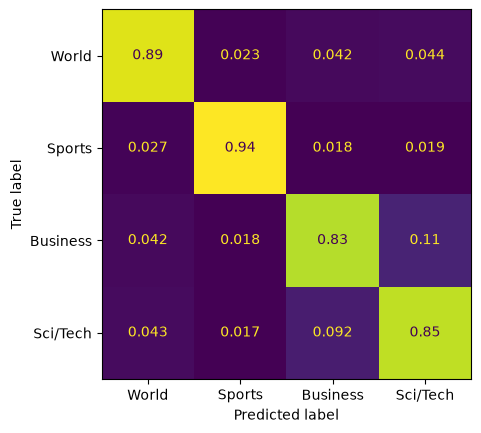

In [29]:
sklearn.metrics.ConfusionMatrixDisplay.from_predictions(test_dataset.labels, y_pred, display_labels=['World', 'Sports', 'Business', 'Sci/Tech'], colorbar=False, normalize='true')